## Data Analysis

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Loading dataset from: d:\University\SEM7\Edge\Project\data\SensorData-v1.csv

--- DATASET INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   time              15000 non-null  float64
 1   target_vel_left   15000 non-null  float64
 2   target_vel_right  15000 non-null  float64
 3   actual_pos_left   15000 non-null  float64
 4   actual_pos_right  15000 non-null  float64
 5   gs_left           15000 non-null  float64
 6   gs_center         15000 non-null  float64
 7   gs_right          15000 non-null  float64
dtypes: float64(8)
memory usage: 937.6 KB
None

--- STATISTICAL SUMMARY ---
               time  target_vel_left  target_vel_right  actual_pos_left  \
count  15000.000000     15000.000000      15000.000000     15000.000000   
mean     240.016000         3.720853          3.209707       889.192481   
std      138.568683         0.699

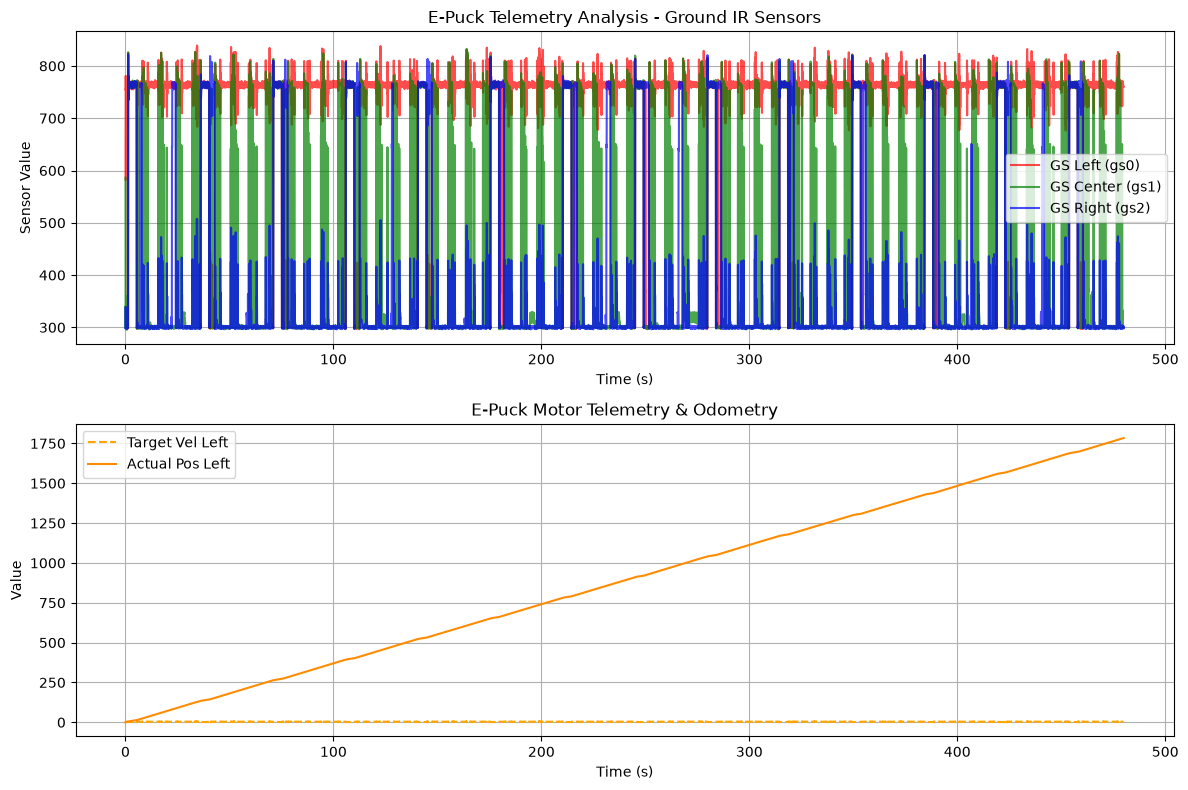

In [4]:
current_dir = Path.cwd()

# Look for 'data' in the current directory or parent directories
root_dir = current_dir
while root_dir != root_dir.parent:
    if (root_dir / "data").exists():
        break
    root_dir = root_dir.parent
else:
    # Fallback to current working directory if not found
    root_dir = current_dir

csv_path = root_dir / "data" / "SensorData-v1.csv"

if not csv_path.exists():
    raise FileNotFoundError(f"Telemetry dataset not found at: {csv_path}. Make sure you ran the Webots simulation first!")

# 2. Load the telemetry dataset
print(f"Loading dataset from: {csv_path}")
df = pd.read_csv(csv_path)

# 3. Basic Inspection
print("\n--- DATASET INFO ---")
print(df.info())

print("\n--- STATISTICAL SUMMARY ---")
print(df.describe())

# 4. Plotting Telemetry Streams
plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)
plt.plot(df['time'], df['gs_left'], label='GS Left (gs0)', color='red', alpha=0.7)
plt.plot(df['time'], df['gs_center'], label='GS Center (gs1)', color='green', alpha=0.7)
plt.plot(df['time'], df['gs_right'], label='GS Right (gs2)', color='blue', alpha=0.7)
plt.title("E-Puck Telemetry Analysis - Ground IR Sensors")
plt.xlabel("Time (s)")
plt.ylabel("Sensor Value")
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(df['time'], df['target_vel_left'], label='Target Vel Left', linestyle='--', color='orange')
plt.plot(df['time'], df['actual_pos_left'], label='Actual Pos Left', color='darkorange')
plt.title("E-Puck Motor Telemetry & Odometry")
plt.xlabel("Time (s)")
plt.ylabel("Value")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()